# Phase 04 · Notebook 4: the connectome with STDP, and the full comparison

## Does the wiring of the connectome bring an advantage in classification or in spike cost?

This notebook closes the modeling phase. It runs the biological network with plasticity, the condition at the core of the research question, and compares it with all the others in a **full factorial design**.

$$\text{topology} \in \{\text{connectome},\ \text{Erdős–Rényi},\ \text{configuration}\}
\ \times\ \text{plasticity} \in \{\text{static},\ \text{STDP+WTA}\}$$

The research question is whether the wiring of the connectome, trained with STDP, beats equivalent artificial wiring. The three arms with plasticity were later extended to **fifteen seeds**, because with five the spread of the degree-preserving control kept the decisive contrast from being resolved. Since they were added after that first result, the [evaluation notebook](../05-evaluation/01-comparative-evaluation.ipynb) also reports the contrast on the added seeds alone. The three static arms keep **five**. That makes 60 runs in total. Contrasts are paired by seed, over the seeds the two arms share.

The six arms share the stimuli, the neuron model, the input layer, the readout and the operating point. Only the wiring changes, and whether the network learns.

This design separates two things that earlier comparisons mixed up, the effect of **topology** and the effect of **plasticity**. Setting a biological network that does not learn against a random network that does learn cannot answer the research question, because both factors change at once.

### Background for readers new to the project

This project asks whether a spiking network wired like an auditory circuit of the fruit fly learns a sound task better than networks of the same size with artificial wiring. The circuit is that of **Johnston's organ** (JO), the fly's ear, taken from the FlyWire **connectome**, the map of all the neurons of the fly brain and of the connections between them (Dorkenwald et al., 2024).

The sound is the **courtship song**, a train of brief song pulses that a male produces by vibrating one wing. The time between consecutive pulses is the **inter-pulse interval** (IPI), one of the cues a female uses to recognize males of her species (Bennet-Clark & Ewing, 1969). The task is to tell apart five songs whose IPIs go from 25 to 65 ms. **Spike encoding** turns each song into spikes for the input layer of the network. A **gammatone filterbank** first splits the sound into 32 frequency bands (Patterson et al., 1992), and an **inner-hair-cell model**, named after the cells that do this in the mammalian ear, turns each band into a firing rate that drives random spikes. The [audio-encoding notebook](01-audio-encoding.ipynb) builds and checks that chain.

In a **spiking neural network** (SNN) neurons communicate with brief electrical events called **spikes**. Ours are **leaky integrate-and-fire** (LIF) neurons with **three synaptic channels**, one excitatory, one inhibitory and one modulatory. Each neuron adds up the current of its channels, leaks it slowly and fires when its voltage crosses a threshold. The networks learn with **spike-timing-dependent plasticity** (STDP), a local rule that strengthens a connection when the sending neuron fires just before the receiving one and weakens it when it fires just after (Song et al., 2000). **Winner-take-all** (WTA) inhibition, a pool of inhibitory neurons, holds the network back when many neurons fire at once, so that a few of them specialize.

The **linear readout** is a logistic regression that names the song from the spike count of each neuron. With five songs the **chance level** is 0.200. The **input-only ceiling**, the accuracy of the same readout applied to the input layer alone, is 0.223. What a network achieves above that ceiling is what the network computes.

The two controls are an **Erdős–Rényi** graph, which places the connections at random, and a **configuration model**, which also keeps how many connections enter and leave each neuron, its **degree**. The readout listens to the 1,116 neurons outside the input layer, over an **integration window** of 250 ms in the main results.

The design has six experimental **arms**: three wirings, each run with static weights and with STDP + WTA. Each arm runs with several **seeds**, the numbers that fix the random generators so that a run can be repeated exactly. A **paired comparison** sets two arms side by side seed by seed, so that only the factor of interest changes. The **effect size**, Cohen's d, measures a difference between arms in units of their standard deviation (Cohen, 1988/2013). The **spikes per correct classification**, all the spikes the network fires during the test divided by the number of correct answers, measure what each answer costs.

The control arms are described in [notebook 2](02-control-networks.ipynb) and the static connectome in [notebook 3](03-connectome-static.ipynb). This notebook brings the six arms together.

## 0. Environment and results

This notebook runs no simulation. The cell loads the subgraph, the operating point of phase 03 and the stored results (`outputs/results.json` and `outputs/extra_seeds.json`), and keeps in `FACTORIAL` the 60 runs of the six arms of the design. The runs with other channel mappings (Section 6) stay in `RES`.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

sys.path.insert(0, str(Path.cwd().parent))
from snnlib import audio as A, evaluation as E, graph, network as NET, FIGURES
from snnlib.evaluation import IPIS, PAIRS, WINDOWS_MS

FIGURES.mkdir(exist_ok=True); OUT_DIR = Path('outputs')
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':150,'savefig.bbox':'tight',
                     'axes.titleweight':'bold','font.size':10})
BLUE, RED, GREEN, PURPLE, GRAY = '#2E86AB','#C73E1D','#3CAEA3','#7B68A6','#8A948F'
COLOR = {'connectome':BLUE, 'er':RED, 'configuration':GREEN}
NAME = {'connectome':'Connectome', 'er':'Erdős–Rényi', 'configuration':'Configuration model'}

C = graph.load()
OP = json.loads((Path('..')/'03-data-preparation'/'outputs'/'operating_point.json').read_text())
RES = E.load_results()   # joins results.json and extra_seeds.json
FACTORIAL = RES[RES.arm.isin(OP['arms'])].copy()
CHANCE = 1/len(IPIS)
per_arm = FACTORIAL.groupby('arm').size()
print(f'Arms: {FACTORIAL.arm.nunique()} · seeds per arm: '
      f'{per_arm.min()} (static) and {per_arm.max()} (with STDP) = {len(FACTORIAL)} runs')
print(f'Task: {len(IPIS)} classes, chance = {CHANCE:.3f}')

Arms: 6 · seeds per arm: 5 (static) and 15 (with STDP) = 60 runs
Task: 5 classes, chance = 0.200


## 1. The biological network with plasticity

STDP acts on the excitatory connections, together with a sparse layer of lateral inhibition (the WTA) that breaks the symmetry between neurons and forces them to specialize. STDP makes the connections onto one neuron compete (Song et al., 2000), but it does not by itself make different neurons learn different inputs. Lateral inhibition adds that competition between neurons (Diehl & Cook, 2015; Masquelier et al., 2009). The parameters come from phase 03.

One implementation detail matters. The weight ceiling `wmax`, the largest value a weight may reach during learning, is set to the **largest initial weight**, not to four times the mean. With the earlier value, 2.70 % of the excitatory connections, which carried 16.7 % of the excitatory weight mass, were clipped at their first update, and that truncation got mixed up with the effect of plasticity.

In [2]:
cfg = OP['arms']['connectome_stdp']
print(f'Calibrated w_input: {cfg["w_input"]:.3f} nA   |   wta_inh = {OP["wta_inh"]} nA')
for k in ['stdp_Aplus','stdp_Aminus','stdp_tau','wta_n','wta_p','wta_exc']:
    print(f'  {k:14s} {NET.P[k]}')
w_exc = C.w[C.mask['Excitatory']]
print(f'\nwmax = max(initial excitatory weight) = {w_exc.max():.3f}')
print(f'  connections clipped before learning: 0 of {len(w_exc):,}')
print(f'  with the earlier criterion (4×mean = {4*w_exc.mean():.3f}) it would have clipped '
      f'{int((w_exc > 4*w_exc.mean()).sum()):,} '
      f'({100*w_exc[w_exc>4*w_exc.mean()].sum()/w_exc.sum():.1f} % of the weight mass)')

Calibrated w_input: 17.556 nA   |   wta_inh = 0.6 nA
  stdp_Aplus     0.05
  stdp_Aminus    0.0525
  stdp_tau       20.0
  wta_n          50
  wta_p          0.25
  wta_exc        1.0

wmax = max(initial excitatory weight) = 15.607
  connections clipped before learning: 0 of 8,512
  with the earlier criterion (4×mean = 3.863) it would have clipped 230 (16.7 % of the weight mass)


The STDP rule is additive and pair-based. Potentiation (`stdp_Aplus` = 0.05) and depression (`stdp_Aminus` = 0.0525) share a time window of 20 ms, and the depression step is 1.05 times the potentiation step, as in Song et al. (2000), so depression slightly outweighs potentiation. Our potentiation step, 0.05 in units of the mean weight, is our own choice for the short training used here; Song et al. express theirs as a fraction of the maximum weight, so the two values are not on the same scale. The WTA layer has 50 interneurons, each connected to 25 % of the network (`wta_p` = 0.25). The weight ceiling `wmax` is 15.607 in normalized units, so no connection is clipped at the start. The earlier criterion (3.863) would have clipped 230 of the 8,512 excitatory connections.

In [3]:
d = FACTORIAL[FACTORIAL.arm=='connectome_stdp']
print('Connectome + STDP + WTA, per seed:\n')
t = pd.DataFrame({'accuracy': d.accuracy.values, 'rate_hz': d.mean_rate_hz.values,
                  'spikes_per_correct': d.spikes_per_correct.values,
                  'selectivity': d.selectivity.values,
                  'mean_dw': d.mean_dw.values,
                  'drift': d.weight_drift.values}, index=d.seed.values)
t.index.name='seed'
pd.concat([t, t.agg(['mean','std'])]).round(4)

Connectome + STDP + WTA, per seed:



,accuracy,rate_hz,spikes_per_correct,selectivity,mean_dw,drift
0,0.9000,17.1428,5899.9889,0.9547,0.5311,0.0122
1,0.8900,17.3811,6049.2135,0.9541,0.5085,0.0071
2,0.8000,20.7706,8042.1000,0.9342,0.7280,0.0168
3,0.9300,20.1544,6712.6989,0.9459,0.5947,0.0157
4,0.8800,19.4945,6861.8409,0.9485,0.6381,0.0209
5,0.8700,18.3938,6548.8391,0.9459,0.5457,0.0119
6,0.8400,13.8957,5124.0476,0.9657,0.3783,0.0065
7,0.8500,15.1860,5533.9412,0.9588,0.5000,0.0056
8,0.8700,17.1392,6102.1379,0.9580,0.4635,0.0125
9,0.9000,18.5565,6386.5333,0.9475,0.6547,0.0260


Over fifteen seeds the connectome with STDP + WTA reaches 0.8753 ± 0.0387, and no seed falls below 0.800 (the best reaches 0.950). Its mean rate, 17.7359 Hz, sits above the 10 Hz operating point because the weights learned with plasticity raise the activity measured in the test. The columns `mean_dw` and `drift` measure how much the weights moved, and the next cell explains them.

### Did learning converge?

The **mean absolute weight change** |Δw| says how far learning moved the weights. The **drift** of the mean weight over the last 20 % of training says whether they were still moving at the end. Small values mean that learning settled. Large ones mean that plasticity had not stabilized and that what gets evaluated is a transient state.

In [4]:
print(f'Mean weight change |Δw|: {d.mean_dw.mean():.4f} ± {d.mean_dw.std():.4f}')
print(f'Final drift of the mean weight: {d.weight_drift.mean():.5f} ± {d.weight_drift.std():.5f}')
print()
stdp_runs = FACTORIAL[FACTORIAL.stdp]
for b in sorted(stdp_runs.arm.unique()):
    x = stdp_runs[stdp_runs.arm==b]
    print(f'  {b:26s} |Δw|={x.mean_dw.mean():.4f}  drift={x.weight_drift.mean():.5f}')

Mean weight change |Δw|: 0.5429 ± 0.0995
Final drift of the mean weight: 0.01236 ± 0.00611

  configuration_stdp         |Δw|=0.8582  drift=0.01465
  connectome_stdp            |Δw|=0.5429  drift=0.01236
  er_stdp                    |Δw|=0.6016  drift=0.02521


The connectome changes its weights the least (|Δw| = 0.5429 ± 0.0995) and ends with the smallest drift (0.01236 ± 0.00611). The configuration model moves its weights more (0.8582) for a similar drift (0.01465). Erdős–Rényi ends with about twice the drift of the connectome (0.02521). All three settle, so the comparison does not evaluate a network caught halfway through learning. The arms are printed in alphabetical order of their names.

## 2. Factorial comparison

This is where the research question gets its answer. For each arm, the table and the figure give the mean over its seeds and the standard deviation of the accuracy. The arms with plasticity have fifteen seeds and the static ones five.

In [5]:
summary = (FACTORIAL.groupby(['topology','stdp'])
           .agg(accuracy=('accuracy','mean'), accuracy_sd=('accuracy','std'),
                rate=('mean_rate_hz','mean'),
                spikes_per_correct=('spikes_per_correct','mean'),
                selectivity=('selectivity','mean'),
                coverage=('coverage_pct','mean'))
           .round(4))
summary

accuracy  accuracy_sd     rate  spikes_per_correct  \
topology      stdp                                                        
configuration False    0.6040       0.0503  10.3203           5325.3870   
              True     0.7680       0.1484  21.5426           9209.2473   
connectome    False    0.5660       0.0820  10.3825           5784.2426   
              True     0.8753       0.0387  17.7359           6277.6494   
er            False    0.4440       0.0568  12.7422           9234.8145   
              True     0.4427       0.0799  33.9374          25175.1348   

                     selectivity  coverage  
topology      stdp                          
configuration False       0.9015   21.8471  
              True        0.9263   11.1763  
connectome    False       0.9127   19.1550  
              True        0.9522    5.8511  
er            False       0.8699   30.2371  
              True        0.9150   11.8341

The table is sorted alphabetically by topology (configuration, connectome, er). With plasticity the connectome reaches the highest accuracy (0.875), ahead of the configuration model (0.768) and far ahead of Erdős–Rényi (0.443). Without plasticity the order is different, and the configuration model (0.604) is slightly ahead of the connectome (0.566). Plasticity raises the firing rate of all three wirings, to 17.7359 Hz in the connectome, 21.5426 Hz in the configuration model and 33.9374 Hz in Erdős–Rényi, against about 10 Hz in the static arms.

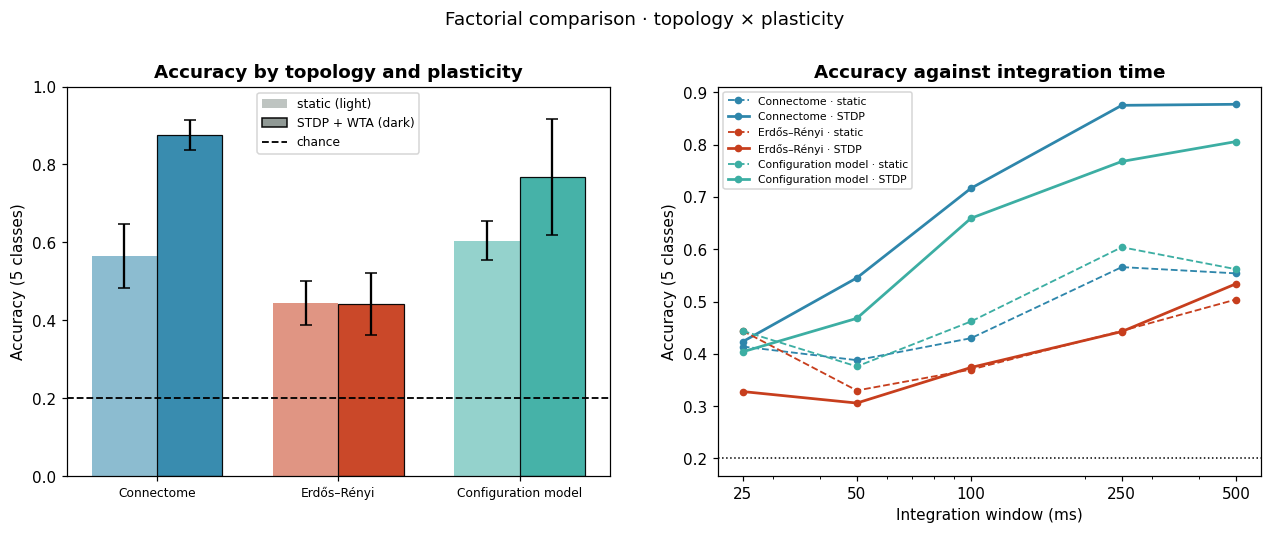

In [6]:
from matplotlib.patches import Patch
fig, ax = plt.subplots(1,2, figsize=(14,4.6))
topos = ['connectome','er','configuration']; x = np.arange(3); an = 0.36
for k,(st,alpha,label) in enumerate([(False,.55,'static'),(True,.95,'STDP + WTA')]):
    m = [FACTORIAL[(FACTORIAL.topology==t)&(FACTORIAL.stdp==st)].accuracy.mean() for t in topos]
    s = [FACTORIAL[(FACTORIAL.topology==t)&(FACTORIAL.stdp==st)].accuracy.std() for t in topos]
    ax[0].bar(x+(k-0.5)*an, m, an, yerr=s, capsize=4, label=label,
              color=[COLOR[t] for t in topos], alpha=alpha,
              edgecolor='k' if st else 'none', linewidth=.8)
ax[0].axhline(CHANCE, color='k', ls='--', lw=1.2, label='chance')
ax[0].set_xticks(x); ax[0].set_xticklabels([NAME[t] for t in topos], fontsize=8)
ax[0].set_ylabel('Accuracy (5 classes)'); ax[0].set_ylim(0,1)
ax[0].legend(handles=[Patch(facecolor=GRAY, alpha=.55, label='static (light)'),
                      Patch(facecolor=GRAY, alpha=.95, edgecolor='k', label='STDP + WTA (dark)'),
                      ax[0].get_lines()[-1]], fontsize=8)
ax[0].set_title('Accuracy by topology and plasticity')

for t in topos:
    for st,ls in [(False,'--'),(True,'-')]:
        sub = FACTORIAL[(FACTORIAL.topology==t)&(FACTORIAL.stdp==st)]
        cur = np.array([list(r.values()) for r in sub.accuracy_vs_window])
        ax[1].plot(WINDOWS_MS, cur.mean(axis=0), ls, color=COLOR[t], marker='o', ms=4,
                   lw=1.8 if st else 1.2,
                   label=f'{NAME[t]} · {"STDP" if st else "static"}')
ax[1].axhline(CHANCE, color='k', ls=':', lw=1)
ax[1].set_xscale('log'); ax[1].set_xticks(WINDOWS_MS); ax[1].set_xticklabels(WINDOWS_MS)
ax[1].set_xlabel('Integration window (ms)'); ax[1].set_ylabel('Accuracy (5 classes)')
ax[1].legend(fontsize=7); ax[1].set_title('Accuracy against integration time')
fig.suptitle('Factorial comparison · topology × plasticity', y=1.03)
fig.savefig(FIGURES/'04-factorial-comparison.png'); plt.show()

Left panel: accuracy by topology and plasticity. Light bars are the static arms, dark bars with an outline the arms with STDP + WTA, and the dashed line is chance. Plasticity lifts the connectome a long way, the configuration model less, and Erdős–Rényi not at all. Right panel: accuracy against the integration window. The connectome with STDP rises from 0.423 at 25 ms to 0.875 at 250 ms and then levels off (0.877 at 500 ms), while the configuration model with STDP keeps rising to the end of the range.

### Statistical contrasts

Each effect is tested separately. A **one-way ANOVA** (analysis of variance) tests whether the mean accuracies of the three topologies differ. A **paired t-test** compares two arms seed by seed. The **p-value** is the probability of seeing a difference at least this large if there were none. Paired contrasts use the seeds the two arms share, so a contrast between a static arm and a plastic one rests on five pairs. The three questions that matter are these.

1. **Topology.** Do the three topologies differ?
2. **Plasticity.** Does STDP improve accuracy within each topology?
3. **Connectome against each control**, separately and for each plasticity condition.

The tests use SciPy (Virtanen et al., 2020). The p-values are not corrected for multiple comparisons.

In [7]:
def paired_ttest(x, y):
    """Paired t-test by seed, truncated to the seeds both arms share.

    The arms with plasticity were extended to fifteen seeds and the static ones
    keep five, so the paired test uses the common prefix of seeds.
    """
    n = min(len(x), len(y))
    return stats.ttest_rel(x[:n], y[:n])

print('Effect of TOPOLOGY (one-way ANOVA, within each plasticity condition):')
for st in [False, True]:
    g = [FACTORIAL[(FACTORIAL.topology==t)&(FACTORIAL.stdp==st)].accuracy.values for t in topos]
    Fst, p = stats.f_oneway(*g)
    print(f'  plasticity={"STDP" if st else "static":8s}  F={Fst:6.2f}  p={p:.5f}'
          f'   means: ' + '  '.join(f'{t}={x.mean():.3f}' for t, x in zip(topos, g)))

print('\nEffect of PLASTICITY (paired t-test by seed, within each topology):')
for t in topos:
    a = FACTORIAL[(FACTORIAL.topology==t)&(~FACTORIAL.stdp)].sort_values('seed').accuracy.values
    b = FACTORIAL[(FACTORIAL.topology==t)&(FACTORIAL.stdp)].sort_values('seed').accuracy.values
    tt, p = paired_ttest(b, a)
    print(f'  {NAME[t]:24s} static={a.mean():.3f}  STDP={b.mean():.3f}  '
          f'Δ={b.mean()-a.mean():+.3f}  t={tt:5.2f}  p={p:.5f}')

print('\nCONNECTOME against each control (paired t-test by seed):')
for st in [False, True]:
    for ctrl in ['er', 'configuration']:
        a = FACTORIAL[(FACTORIAL.topology=='connectome')&(FACTORIAL.stdp==st)].sort_values('seed').accuracy.values
        b = FACTORIAL[(FACTORIAL.topology==ctrl)&(FACTORIAL.stdp==st)].sort_values('seed').accuracy.values
        tt, p = paired_ttest(a, b)
        print(f'  {"STDP" if st else "static":9s} connectome vs {ctrl:14s} '
              f'Δ={a.mean()-b.mean():+.3f}  t={tt:5.2f}  p={p:.5f}')

Effect of TOPOLOGY (one-way ANOVA, within each plasticity condition):
  plasticity=static    F=  8.39  p=0.00525   means: connectome=0.566  er=0.444  configuration=0.604
  plasticity=STDP      F= 76.38  p=0.00000   means: connectome=0.875  er=0.443  configuration=0.768

Effect of PLASTICITY (paired t-test by seed, within each topology):
  Connectome               static=0.566  STDP=0.875  Δ=+0.309  t= 5.69  p=0.00471


  Erdős–Rényi              static=0.444  STDP=0.443  Δ=-0.001  t=-0.41  p=0.70578
  Configuration model      static=0.604  STDP=0.768  Δ=+0.164  t= 1.48  p=0.21314

CONNECTOME against each control (paired t-test by seed):
  static    connectome vs er             Δ=+0.122  t= 2.95  p=0.04210
  static    connectome vs configuration  Δ=-0.038  t=-0.96  p=0.38965
  STDP      connectome vs er             Δ=+0.433  t=19.84  p=0.00000
  STDP      connectome vs configuration  Δ=+0.107  t= 2.72  p=0.01671


**Topology matters in both conditions.** The ANOVA gives F = 8.39, p = 0.00525 for the static arms and F = 76.38, p < 0.00001 with plasticity (the cell prints 0.00000 at five decimals).

**Plasticity pays off significantly only on the connectome.** It improves the connectome by +0.309 (t = 5.69, p = 0.00471). It improves the configuration model by +0.164, which is not significant (p = 0.21314), and it leaves Erdős–Rényi where it was (−0.001, p = 0.70578). The pattern points to an **interaction** between topology and plasticity, where the effect of one factor depends on the other. The [evaluation notebook](../05-evaluation/01-comparative-evaluation.ipynb) tests it directly. The gain of the connectome is larger than that of Erdős–Rényi (p = 0.0114) but not significantly larger than that of the configuration model (p = 0.0988). Plasticity here also means the WTA layer, which the static arms lack. The +0.309 compares the fifteen plastic seeds with the five static ones. On the five seeds the two arms share, which are the ones the test uses, the gain is +0.314.

**Against each control.** Without plasticity the connectome beats Erdős–Rényi (+0.122, p = 0.04210) but not the configuration model (−0.038, p = 0.38965). With plasticity it beats both, by +0.433 over Erdős–Rényi (t = 19.84, p < 0.00001) and by +0.107 over the configuration model (t = 2.72, p = 0.01671). The last contrast is the decisive one, because that control keeps, almost exactly, the degree sequence of the connectome. The [evaluation notebook of phase 05](../05-evaluation/01-comparative-evaluation.ipynb) adds the effect sizes: d = 1.02 for this contrast and d = 7.14 against Erdős–Rényi with STDP.

## 3. Efficiency: accuracy per spike

For neuromorphic computing the criterion is not only to be right but also the cost of being right. On event-driven chips such as Loihi, energy is spent only when spikes occur (Schuman et al., 2022), and each synaptic spike operation costs at least 23.6 pJ (Davies et al., 2018). The relevant measure here is therefore how many spikes each correct classification takes.

This comparison also corrects an imbalance. The operating point was matched **before** learning, but plasticity shifts the activity of the network. The arms with STDP end up firing more than the static ones, so comparing them on accuracy alone would favor them. Looking at accuracy against the spike budget puts every arm on the same scale.

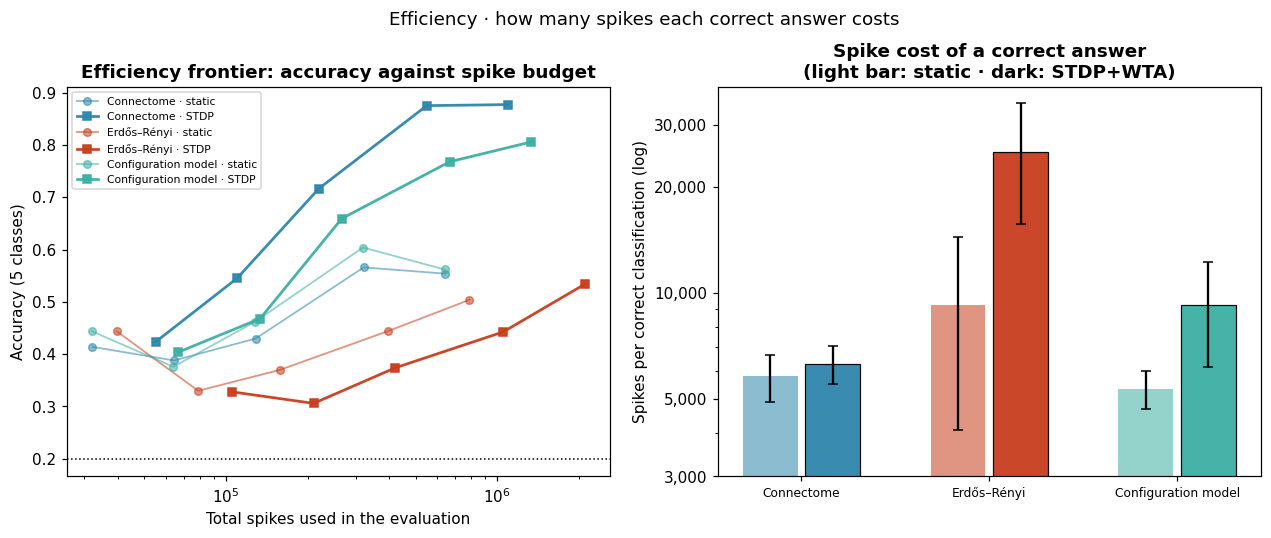

Spikes per correct classification (mean ± standard deviation):
  Connectome               static        5,784 ±     886
  Connectome               STDP          6,278 ±     790
  Erdős–Rényi              static        9,235 ±   5,154
  Erdős–Rényi              STDP         25,175 ±   9,453
  Configuration model      static        5,325 ±     662
  Configuration model      STDP          9,209 ±   3,052


In [8]:
fig, ax = plt.subplots(1,2, figsize=(14,4.6))
labels=[]
for t in topos:
    for st,alpha,mk in [(False,.55,'o'),(True,.95,'s')]:
        sub = FACTORIAL[(FACTORIAL.topology==t)&(FACTORIAL.stdp==st)]
        cur = np.array([list(r.values()) for r in sub.accuracy_vs_window])
        # spikes ≈ proportional to the integration window
        spikes = np.array([sub.test_spikes.mean()*v/sub.main_window_ms.mean()
                           for v in WINDOWS_MS])
        ax[0].plot(spikes, cur.mean(axis=0), '-'+mk, color=COLOR[t], ms=5,
                   alpha=alpha, lw=1.8 if st else 1.2,
                   label=f'{NAME[t]} · {"STDP" if st else "static"}')
ax[0].axhline(CHANCE, color='k', ls=':', lw=1)
ax[0].set_xscale('log'); ax[0].set_xlabel('Total spikes used in the evaluation')
ax[0].set_ylabel('Accuracy (5 classes)'); ax[0].legend(fontsize=7)
ax[0].set_title('Efficiency frontier: accuracy against spike budget')

vals = [FACTORIAL[(FACTORIAL.topology==t)&(FACTORIAL.stdp==st)].spikes_per_correct
        for t in topos for st in [False,True]]
pos = [0,.4, 1.2,1.6, 2.4,2.8]
cols = [COLOR[t] for t in topos for _ in (0,1)]
alphas = [.55,.95]*3
for p_,v,c,al in zip(pos, vals, cols, alphas):
    ax[1].bar(p_, v.mean(), .35, yerr=v.std(), color=c, alpha=al, capsize=3,
              edgecolor='k' if al>.9 else 'none', linewidth=.8)
ax[1].set_yscale('log')
ax[1].set_yticks([3000, 5000, 10000, 20000, 30000], ['3,000', '5,000', '10,000', '20,000', '30,000'])
ax[1].set_xticks([.2,1.4,2.6]); ax[1].set_xticklabels([NAME[t] for t in topos], fontsize=8)
ax[1].set_ylabel('Spikes per correct classification (log)')
ax[1].set_title('Spike cost of a correct answer\n(light bar: static · dark: STDP+WTA)')
fig.suptitle('Efficiency · how many spikes each correct answer costs', y=1.03)
fig.savefig(FIGURES/'04-spike-efficiency-frontier.png'); plt.show()

print('Spikes per correct classification (mean ± standard deviation):')
for t in topos:
    for st in [False,True]:
        v = FACTORIAL[(FACTORIAL.topology==t)&(FACTORIAL.stdp==st)].spikes_per_correct
        print(f'  {NAME[t]:24s} {"STDP" if st else "static":9s} {v.mean():9,.0f} ± {v.std():7,.0f}')

Left panel: accuracy against the total number of spikes used in the evaluation, assuming the spike count grows in proportion to the integration window. The connectome with STDP reaches every level of accuracy with fewer spikes than the other plastic arms. Right panel: spikes per correct classification, on a logarithmic axis.

The connectome with STDP spends 6,278 ± 790 spikes per correct answer. Erdős–Rényi with the same plasticity spends 25,175 ± 9,453, 4.0 times more, for half the accuracy. Against the configuration model with STDP (9,209 ± 3,052), the connectome is more accurate and spends 31.8 % fewer spikes. Among the static arms the connectome is competitive but not the cheapest (5,784 ± 886 against 5,325 ± 662 for the configuration model). The efficiency advantage appears when plasticity comes in.

These are spike counts, not energy. The [comparison with conventional networks](results.md#11-comparison-with-conventional-networks) in the results of this phase shows that, on this task, a linear classifier is far cheaper than any of these spiking networks.

## 4. Difficulty gradient

Here the question changes. Instead of "which of the five songs was it?", the readout only has to tell **two** apart. It is an easier task, with chance at **0.500** instead of 0.200, so these numbers are not compared with those of Section 2. The five pairs come from the same set of responses, by restricting the readout to two classes. There are no new simulations.

What orders the pairs is not the difference in milliseconds but the **relative** difference. `Hard` (35 vs 45 ms) and `Very hard` (45 vs 55 ms) are both 10 ms apart. Ten milliseconds on a base of 35 is 29 % of the interval, and on a base of 45 only 22 %. This is Weber's law: what is registered of a change is its proportion, not its absolute size (Gibbon, 1977). The series therefore runs from 160 % down to 22 %.

The pair **35 vs 55 ms** separates a song typical of *D. melanogaster* (about 34 ms) from one in the range reported for *D. simulans* (50–65 ms; Bennet-Clark & Ewing, 1969; Deutsch et al., 2019).

In [9]:
rows=[]
for t in topos:
    for st in [False,True]:
        sub = FACTORIAL[(FACTORIAL.topology==t)&(FACTORIAL.stdp==st)]
        row = {'topology':NAME[t], 'plasticity':'STDP+WTA' if st else 'static'}
        for n,_,_ in PAIRS:
            v = np.array([p[n] for p in sub.pair_accuracy])
            row[n] = round(v.mean(),3)
        rows.append(row)
gradient = pd.DataFrame(rows).set_index(['topology','plasticity'])
gradient

Very easy   Easy  Medium   Hard  Very hard
topology            plasticity                                            
Connectome          static          0.970  0.920   0.900  0.810      0.750
                    STDP+WTA        1.000  0.997   0.998  0.983      0.955
Erdős–Rényi         static          0.920  0.910   0.845  0.630      0.650
                    STDP+WTA        0.933  0.905   0.848  0.672      0.682
Configuration model static          0.980  0.995   0.970  0.900      0.785
                    STDP+WTA        0.990  0.995   0.983  0.950      0.927

The connectome with STDP + WTA comes first on all five pairs: 1.000, 0.997, 0.998, 0.983 and 0.955. On the pair that separates the two species (35 vs 55 ms) it reaches 0.998. On the hardest pair it keeps 0.955, where Erdős–Rényi with STDP stays at 0.682. In four arms the hardest pair comes out worse than `Hard`, as the relative difference predicts. The two Erdős–Rényi arms are the exception, with the two hard pairs close to each other and not far above chance.

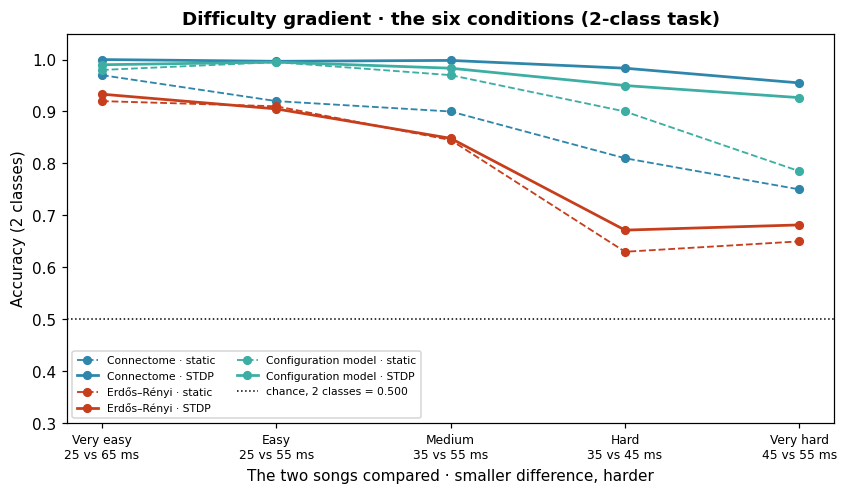

In [10]:
fig, ax = plt.subplots(figsize=(9,4.6))
names=[p[0] for p in PAIRS]
labels=[f'{n}\n{a} vs {b} ms' for n,a,b in PAIRS]
x=np.arange(len(names))
for t in topos:
    for st,ls in [(False,'--'),(True,'-')]:
        sub = FACTORIAL[(FACTORIAL.topology==t)&(FACTORIAL.stdp==st)]
        m=[np.mean([p[n] for p in sub.pair_accuracy]) for n in names]
        ax.plot(x, m, ls, marker='o', ms=5, color=COLOR[t], lw=1.8 if st else 1.2,
                label=f'{NAME[t]} · {"STDP" if st else "static"}')
ax.axhline(.5, color='k', ls=':', lw=1, label='chance, 2 classes = 0.500')
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel('Accuracy (2 classes)')
ax.set_xlabel('The two songs compared · smaller difference, harder')
ax.set_ylim(.3,1.05); ax.legend(fontsize=7, ncol=2, loc='lower left')
ax.set_title('Difficulty gradient · the six conditions (2-class task)')
fig.savefig(FIGURES/'04-difficulty-gradient.png'); plt.show()

The figure draws the same table, one line per arm, with the two-class chance level (0.500) as a dotted line. The plastic arms are the solid lines. The gap between the connectome with STDP and the rest widens as the pairs get harder.

## 5. Selectivity and representation

**Selectivity** is the population sparseness of the response, $S = [1 - (\sum r/n)^2 / \sum (r^2/n)] / (1 - 1/n)$, where $r$ are the responses of the $n$ readout neurons. It is the normalized Treves–Rolls measure (Treves & Rolls, 1991; Vinje & Gallant, 2000) computed across neurons (Willmore & Tolhurst, 2001). It is 0 when all neurons respond equally and 1 when a single neuron responds. **Coverage** is the percentage of the readout population that fires at least once during a song.

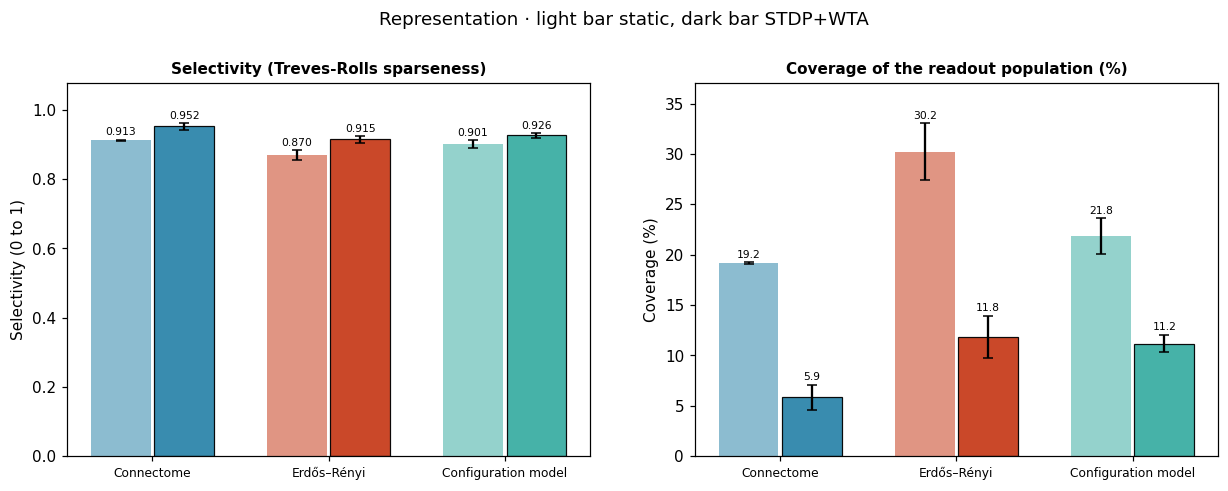

In [11]:
fig, ax = plt.subplots(1,2, figsize=(13.5,4.4))
for i,(col,title,ylab,fmt) in enumerate([('selectivity','Selectivity (Treves-Rolls sparseness)','Selectivity (0 to 1)','{:.3f}'),
                              ('coverage_pct','Coverage of the readout population (%)','Coverage (%)','{:.1f}')]):
    for j,t in enumerate(topos):
        for k,st in enumerate([False,True]):
            v = FACTORIAL[(FACTORIAL.topology==t)&(FACTORIAL.stdp==st)][col]
            ax[i].bar(j+(k-.5)*.36, v.mean(), .34, yerr=v.std(), color=COLOR[t],
                      alpha=.55 if not st else .95, capsize=3,
                      edgecolor='k' if st else 'none', linewidth=.8)
            ax[i].annotate(fmt.format(v.mean()), (j+(k-.5)*.36, v.mean()+v.std()),
                           xytext=(0, 3), textcoords='offset points', ha='center', fontsize=7)
    ax[i].set_xticks(range(3)); ax[i].set_xticklabels([NAME[t] for t in topos], fontsize=8)
    ax[i].set_ylabel(ylab); ax[i].margins(y=.12)
    ax[i].set_title(title, fontsize=10)
fig.suptitle('Representation · light bar static, dark bar STDP+WTA', y=1.03)
fig.savefig(FIGURES/'04-representation.png'); plt.show()

Plasticity raises the selectivity of the three wirings, and the connectome with STDP has the highest (0.952). It also shrinks coverage. In the connectome with STDP only 5.851 % of the readout neurons fire at least once, against 19.155 % in the static connectome. Learning concentrates the response on a small group of neurons, and in the connectome that small group is also the one that classifies best.

## 6. The channel-to-neuron mapping

With the JO-A and JO-B subtypes available, the mapping of filterbank channels onto input neurons can be anchored to anatomy. We compare four variants (anchored, inverted, `root_id` order and random) to check that the result is not an artifact of one particular assignment. Each mapping runs with five seeds, static and with STDP + WTA.

In [12]:
from scipy import stats as st_
MAPPINGS=['subtype','subtype_inverted','root_id','random']
print(f'{"channel mapping":24s}{"static":>18}{"STDP+WTA":>18}')
for k in MAPPINGS:
    e=RES[RES.arm==f'mapping_{k}_static'].accuracy
    d_=RES[RES.arm==f'mapping_{k}_stdp'].accuracy
    print(f'{k:24s}{e.mean():11.3f}±{e.std():5.3f}{d_.mean():11.3f}±{d_.std():5.3f}')
a=RES[RES.arm=='mapping_subtype_static'].sort_values('seed').accuracy.values
b=RES[RES.arm=='mapping_random_static'].sort_values('seed').accuracy.values
print(f'\nAnchored against random (static): {a.mean()-b.mean():+.3f}  p={st_.ttest_rel(a,b).pvalue:.4f}')
c_=RES[RES.arm=='mapping_subtype_inverted_static'].sort_values('seed').accuracy.values
print(f'Anchored against its inverse:     {a.mean()-c_.mean():+.3f}  p={st_.ttest_rel(a,c_).pvalue:.4f}')
print()
print('In this task tonotopic anchoring does NOT help, and that was expected: the five')
print('songs share the carrier, so there is no frequency axis to exploit. Every')
print('mapping drives the same number of input neurons; what changes is which ones,')
print('and so which partners downstream receive the song.')
print()
print('The main results use the anchored mapping, the least favorable one for the')
print('accuracy of the connectome. The control networks ran only with this mapping.')

channel mapping                     static          STDP+WTA
subtype                       0.566±0.082      0.880±0.048
subtype_inverted              0.758±0.044      0.900±0.040
root_id                       0.676±0.044      0.892±0.016
random                        0.736±0.045      0.920±0.029

Anchored against random (static): -0.170  p=0.0327
Anchored against its inverse:     -0.192  p=0.0151

In this task tonotopic anchoring does NOT help, and that was expected: the five
songs share the carrier, so there is no frequency axis to exploit. Every
mapping drives the same number of input neurons; what changes is which ones,
and so which partners downstream receive the song.

The main results use the anchored mapping, the least favorable one for the
accuracy of the connectome. The control networks ran only with this mapping.


With plasticity the connectome reaches between 0.880 and 0.920 under the four mappings: 0.880 ± 0.048 anchored, 0.900 ± 0.040 inverted, 0.892 ± 0.016 by `root_id` and 0.920 ± 0.029 random. The anchored value is the mean of the first five seeds of the main arm, which the code reproduces exactly when it runs the same configuration again. Without plasticity the anchored mapping is clearly the worst, 0.170 below the random one (p = 0.0327) and 0.192 below its inverse (p = 0.0151), both paired by seed. The accuracy of the connectome with plasticity does not depend much on the mapping. Its gain from plasticity does. On these five seeds it is +0.314 with the anchored mapping and between +0.142 and +0.216 with the other three, because the static connectome does worst with the anchored one. The control networks ran only with the anchored mapping, so whether they would gain or lose with the others is untested.

## 7. Conclusions

We draw the conclusions from the numbers of this notebook. The next cell gathers them so that the reading is direct and can be checked.

In [13]:
print('='*72)
print('QUANTITATIVE SUMMARY'.center(72))
print('='*72)
print(f'\nTask: tell apart {len(IPIS)} inter-pulse intervals of the courtship song.'
      f'  Chance = {CHANCE:.3f}')
print(f'Design: 3 topologies × 2 plasticity conditions, '
      f'{FACTORIAL.groupby("arm").size().min()} seeds per static arm and '
      f'{FACTORIAL.groupby("arm").size().max()} per arm with STDP,')
print(f'        operating point matched at {OP["target_hz"]} Hz\n')
print(f'{"":30s}{"accuracy":>18}{"spikes/correct":>18}{"selectivity":>14}')
for t in topos:
    for st in [False,True]:
        s_ = FACTORIAL[(FACTORIAL.topology==t)&(FACTORIAL.stdp==st)]
        label = f'{NAME[t]} · {"STDP" if st else "static"}'
        print(f'{label:30s}{s_.accuracy.mean():10.3f}±{s_.accuracy.std():5.3f}'
              f'{s_.spikes_per_correct.mean():14,.0f}{s_.selectivity.mean():14.3f}')

best = FACTORIAL.groupby('arm').accuracy.mean().idxmax()
most_efficient = FACTORIAL.groupby('arm').spikes_per_correct.mean().idxmin()
print(f'\nHighest accuracy:  {best}')
print(f'Lowest cost in spikes per correct classification: {most_efficient}')

print('\nMain contrasts (paired t-test by seed):')
for st in [False,True]:
    for ctrl in ['er','configuration']:
        a = FACTORIAL[(FACTORIAL.topology=='connectome')&(FACTORIAL.stdp==st)].sort_values('seed').accuracy.values
        b = FACTORIAL[(FACTORIAL.topology==ctrl)&(FACTORIAL.stdp==st)].sort_values('seed').accuracy.values
        n_=min(len(a),len(b)); tt,p = stats.ttest_rel(a[:n_],b[:n_])
        verdict = 'connectome better' if (p<.05 and a.mean()>b.mean()) else (
                    f'{ctrl} better' if (p<.05) else 'no significant difference')
        print(f'  {"STDP" if st else "static":9s} connectome vs {ctrl:14s} '
              f'Δ={a.mean()-b.mean():+.3f}  p={p:.4f}  →  {verdict}')
for t in topos:
    a = FACTORIAL[(FACTORIAL.topology==t)&(~FACTORIAL.stdp)].sort_values('seed').accuracy.values
    b = FACTORIAL[(FACTORIAL.topology==t)&(FACTORIAL.stdp)].sort_values('seed').accuracy.values
    n_=min(len(a),len(b)); tt,p = stats.ttest_rel(b[:n_],a[:n_])
    verdict = 'STDP improves' if (p<.05 and b.mean()>a.mean()) else (
                'STDP worsens' if p<.05 else 'no significant effect')
    print(f'  plasticity in {NAME[t]:24s} Δ={b.mean()-a.mean():+.3f}  p={p:.4f}  →  {verdict}')
print('='*72)

                          QUANTITATIVE SUMMARY                          

Task: tell apart 5 inter-pulse intervals of the courtship song.  Chance = 0.200
Design: 3 topologies × 2 plasticity conditions, 5 seeds per static arm and 15 per arm with STDP,
        operating point matched at 10.0 Hz

                                        accuracy    spikes/correct   selectivity
Connectome · static                0.566±0.082         5,784         0.913
Connectome · STDP                  0.875±0.039         6,278         0.952
Erdős–Rényi · static               0.444±0.057         9,235         0.870
Erdős–Rényi · STDP                 0.443±0.080        25,175         0.915
Configuration model · static       0.604±0.050         5,325         0.901
Configuration model · STDP         0.768±0.148         9,209         0.926

Highest accuracy:  connectome_stdp
Lowest cost in spikes per correct classification: configuration_static

Main contrasts (paired t-test by seed):
  static    connectome vs 

1. **The connectome with plasticity is the best of the six arms** (0.875 ± 0.039 over fifteen seeds) and beats each of the other five with statistical significance, including the control that keeps its degree sequence (+0.107, p = 0.0167).
2. **Plasticity pays off significantly only on the biological wiring.** The same rule gives +0.309 on the connectome, a non-significant +0.164 on the configuration model and nothing on Erdős–Rényi. This pattern is the central finding of the phase; tested directly, the interaction is significant against Erdős–Rényi but not against the configuration model.
3. **Without plasticity the advantage is small.** The static connectome beats Erdős–Rényi but not the configuration model. On its own, the wiring adds little. What it adds is being the right substrate for plasticity to work on.
4. **Spike cost.** The connectome with STDP needs 4.0 times fewer spikes per correct answer than Erdős–Rényi with STDP, for twice the accuracy. The lowest spike cost of all belongs to the static configuration model, which is much less accurate.

These conclusions carry the limitations listed in the [results of this phase](results.md#limitations). The task is a proxy and the p-values are not corrected here. Plasticity also comes with the WTA layer, ten seeds were added after a first result, and the channel mappings were tested only on the connectome.

These are comparisons between spiking networks. They do not show an energy advantage over conventional networks, and the [results of this phase](results.md#11-comparison-with-conventional-networks) explain why that claim cannot be made for this task.

The numerical results and their reading are gathered in the [results of this phase](results.md). The design decisions and how they changed over time are in the [research log](research-log.md).

## References

- Bennet-Clark, H. C., & Ewing, A. W. (1969). Pulse interval as a critical parameter in the courtship song of *Drosophila melanogaster*. *Animal Behaviour, 17*(4), 755–759. https://doi.org/10.1016/S0003-3472(69)80023-0
- Cohen, J. (2013). *Statistical power analysis for the behavioral sciences* (2nd ed.). Routledge. https://doi.org/10.4324/9780203771587 (Original work published 1988)
- Davies, M., Srinivasa, N., Lin, T.-H., Chinya, G., Cao, Y., Choday, S. H., Dimou, G., Joshi, P., Imam, N., Jain, S., Liao, Y., Lin, C.-K., Lines, A., Liu, R., Mathaikutty, D., McCoy, S., Paul, A., Tse, J., Venkataramanan, G., . . . Wang, H. (2018). Loihi: A neuromorphic manycore processor with on-chip learning. *IEEE Micro, 38*(1), 82–99. https://doi.org/10.1109/MM.2018.112130359
- Deutsch, D., Clemens, J., Thiberge, S. Y., Guan, G., & Murthy, M. (2019). Shared song detector neurons in *Drosophila* male and female brains drive sex-specific behaviors. *Current Biology, 29*(19), 3200–3215.e5. https://doi.org/10.1016/j.cub.2019.08.008
- Diehl, P. U., & Cook, M. (2015). Unsupervised learning of digit recognition using spike-timing-dependent plasticity. *Frontiers in Computational Neuroscience, 9*, Article 99. https://doi.org/10.3389/fncom.2015.00099
- Dorkenwald, S., Matsliah, A., Sterling, A. R., Schlegel, P., Yu, S.-c., McKellar, C. E., Lin, A., Costa, M., Eichler, K., Yin, Y., Silversmith, W., Schneider-Mizell, C., Jordan, C. S., Brittain, D., Halageri, A., Kuehner, K., Ogedengbe, O., Morey, R., Gager, J., . . . The FlyWire Consortium. (2024). Neuronal wiring diagram of an adult brain. *Nature, 634*(8032), 124–138. https://doi.org/10.1038/s41586-024-07558-y
- Gibbon, J. (1977). Scalar expectancy theory and Weber’s law in animal timing. *Psychological Review, 84*(3), 279–325. https://doi.org/10.1037/0033-295X.84.3.279
- Masquelier, T., Guyonneau, R., & Thorpe, S. J. (2009). Competitive STDP-based spike pattern learning. *Neural Computation, 21*(5), 1259–1276. https://doi.org/10.1162/neco.2008.06-08-804
- Patterson, R. D., Robinson, K., Holdsworth, J., McKeown, D., Zhang, C., & Allerhand, M. (1992). Complex sounds and auditory images. In Y. Cazals, L. Demany, & K. Horner (Eds.), *Auditory physiology and perception* (pp. 429–446). Pergamon. https://doi.org/10.1016/B978-0-08-041847-6.50054-X
- Schuman, C. D., Kulkarni, S. R., Parsa, M., Mitchell, J. P., Date, P., & Kay, B. (2022). Opportunities for neuromorphic computing algorithms and applications. *Nature Computational Science, 2*(1), 10–19. https://doi.org/10.1038/s43588-021-00184-y
- Song, S., Miller, K. D., & Abbott, L. F. (2000). Competitive Hebbian learning through spike-timing-dependent synaptic plasticity. *Nature Neuroscience, 3*(9), 919–926. https://doi.org/10.1038/78829
- Treves, A., & Rolls, E. T. (1991). What determines the capacity of autoassociative memories in the brain? *Network: Computation in Neural Systems, 2*(4), 371–397. https://doi.org/10.1088/0954-898X_2_4_004
- Vinje, W. E., & Gallant, J. L. (2000). Sparse coding and decorrelation in primary visual cortex during natural vision. *Science, 287*(5456), 1273–1276. https://doi.org/10.1126/science.287.5456.1273
- Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., Burovski, E., Peterson, P., Weckesser, W., Bright, J., van der Walt, S. J., Brett, M., Wilson, J., Millman, K. J., Mayorov, N., Nelson, A. R. J., Jones, E., Kern, R., Larson, E., . . . Vázquez-Baeza, Y. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*(3), 261–272. https://doi.org/10.1038/s41592-019-0686-2
- Willmore, B., & Tolhurst, D. J. (2001). Characterizing the sparseness of neural codes. *Network: Computation in Neural Systems, 12*(3), 255–270. https://doi.org/10.1080/net.12.3.255.270